INPUT GAM DATA
Input file: /gws/ssde/j25a/acure/jianxing/aci/GAM_values/ACI/summary/ACI_GAM_relative_importance_optimal_constrained.csv
Number of rows: 194324
Clusters: ['c1', 'c5', 'c7']
Months: ['ann', 'apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']

BUILD ALL-MONTH TOP 4 + LIN'S CCC RESULTS

Cluster 1 Jan TOP 4 + LIN'S CCC RESULT
Number of grid boxes: 120
Top parameters: ['dry_dep_acc', 'prim_so4_diam', 'bc_ri', 'sig_w']

        param  cluster_mean_signed_response  abs_after_sign_mean  cluster_month_pct
  dry_dep_acc                    -14.387039            14.387039          23.206806
prim_so4_diam                     -9.148139             9.148139          14.756273
        bc_ri                      7.342314             7.342314          11.843414
        sig_w                     -4.728631             4.728631           7.627450

Number of high-similarity grid boxes (CCC >= 0.9): 4
Number of negative CCC values: 21

Cluster 1 Feb TOP 4 + LIN'

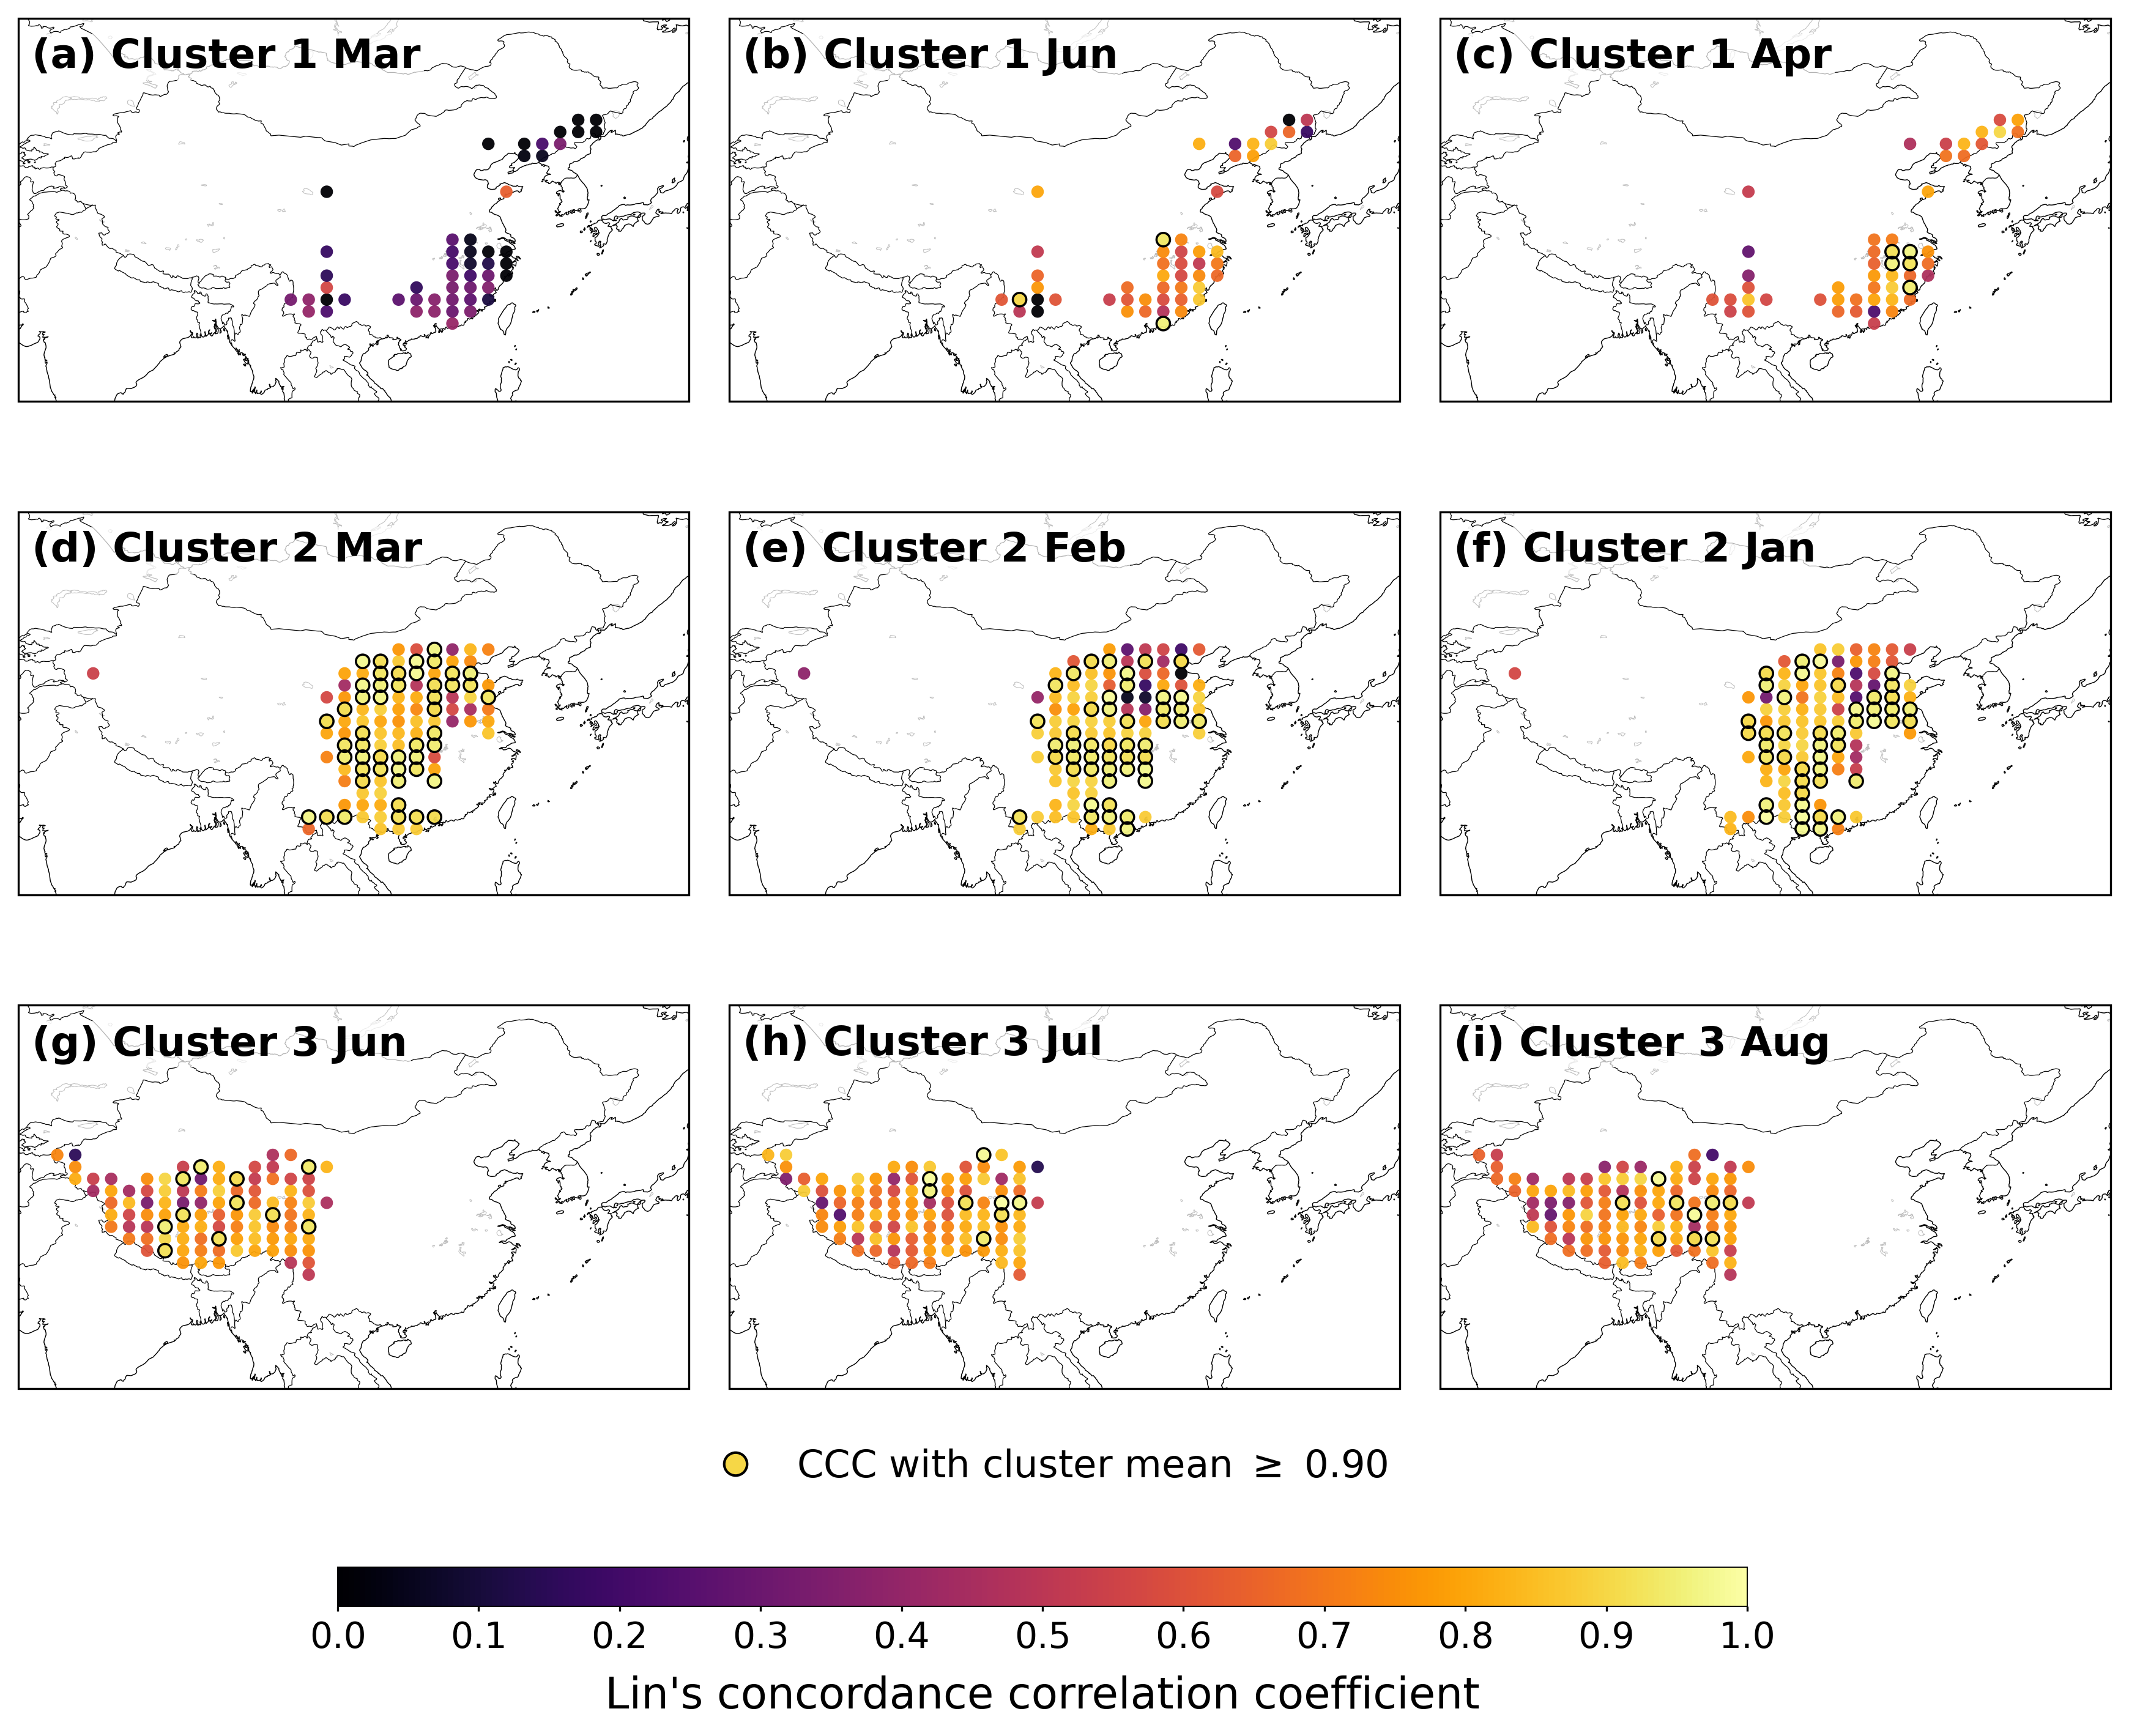


Done. No files were saved. The selected-month CCC figure was displayed directly in the notebook.


In [5]:
# ============================================================
# Selected-month similarity maps for ACI clusters
#
# Optimal constrained case only
#
# Top 4 comparison version:
#
#   1. Similarity parameters are selected using:
#
#          Top 4 cluster_month_pct parameters
#
#      for each cluster-month separately.
#
#   2. Selected months are:
#
#          Cluster 1 / c1: Mar, Jun, Apr
#          Cluster 2 / c5: Mar, Feb, Jan
#          Cluster 3 / c7: Jun, Jul, Aug
#
#   3. Only plot the selected-month CCC figure.
#
#   4. No figures or CSV files are saved.
#      The figure is displayed directly in the notebook.
#
#   5. No seed point is specially plotted.
#
#   6. All grid boxes with:
#
#          CCC >= 0.90
#
#      are circled with a black open circle.
#
# ============================================================


# ==== 导入库 ====

import os
import re

import numpy as np
import xarray as xr
import iris
import scipy.ndimage

from tqdm import tqdm

import pandas as pd

import matplotlib as mp
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

from shapely.geometry import Point
from shapely.ops import unary_union

from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm,
    LinearSegmentedColormap,
    Normalize
)

from matplotlib.lines import Line2D


# ============================================================
# ==== CONFIGURATION ====
# ============================================================

infile = (
    "/gws/ssde/j25a/acure/jianxing/aci/"
    "GAM_values/ACI/summary/"
    "ACI_GAM_relative_importance_optimal_constrained.csv"
)


# ============================================================
# ==== CLUSTER SETTINGS ====
# ============================================================

clusters = [
    "c1",
    "c5",
    "c7"
]

cluster_ids = [
    1.0,
    5.0,
    7.0
]

cluster_id_to_name = {
    1.0: "c1",
    5.0: "c5",
    7.0: "c7"
}

cluster_name_to_id = {
    "c1": 1.0,
    "c5": 5.0,
    "c7": 7.0
}

cluster_label_map = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}

cluster_color_map = {
    "c1": "#ff7f0e",
    "c5": "#966150",
    "c7": "#8d8d8d"
}

cluster_cmap = ListedColormap([
    cluster_color_map["c1"],
    cluster_color_map["c5"],
    cluster_color_map["c7"]
])

cluster_bounds = [
    0.5,
    3.0,
    6.0,
    7.5
]

cluster_norm = BoundaryNorm(
    cluster_bounds,
    cluster_cmap.N
)


# ============================================================
# ==== MONTH SETTINGS ====
# ============================================================

all_months = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

selected_months_by_cluster = {
    "c1": [
        "mar",
        "jun",
        "apr"
    ],

    "c5": [
        "mar",
        "feb",
        "jan"
    ],

    "c7": [
        "jun",
        "jul",
        "aug"
    ]
}

month_label_map = {
    "jan": "Jan",
    "feb": "Feb",
    "mar": "Mar",
    "apr": "Apr",
    "may": "May",
    "jun": "Jun",
    "jul": "Jul",
    "aug": "Aug",
    "sep": "Sep",
    "oct": "Oct",
    "nov": "Nov",
    "dec": "Dec"
}


# ============================================================
# ==== REPRESENTATIVE-POINT SETTINGS ====
# ============================================================

top_n = 4

# 保持原程序：
# CCC >= 0.90
ccc_threshold = 0.90

lat_min = 15
lat_max = 55

lon_min = 70
lon_max = 140

china_extent = [
    lon_min,
    lon_max,
    lat_min,
    lat_max
]

grid_key_ndigits = 2


# ============================================================
# ==== CHINA BOUNDARY FOR FINAL PLOTTING ONLY ====
#
# Important:
#   This boundary mask is used ONLY when plotting the final
#   selected-month CCC maps. It does NOT change the previous
#   Top-4 selection, cluster mean, CCC calculation, seed point,
#   or high-similarity classification.
# ============================================================

china_boundary_shapefile = shpreader.natural_earth(
    resolution="50m",
    category="cultural",
    name="admin_0_countries"
)

china_geometries = []

for record in shpreader.Reader(
    china_boundary_shapefile
).records():

    attributes = record.attributes

    if (
        attributes.get("ADM0_A3") == "CHN"
        or attributes.get("ADMIN") == "China"
        or attributes.get("NAME_LONG") == "China"
    ):

        china_geometries.append(
            record.geometry
        )

if len(
    china_geometries
) == 0:

    raise ValueError(
        "China geometry was not found in the "
        "Natural Earth admin_0_countries dataset."
    )

china_geometry = unary_union(
    china_geometries
)


# ============================================================
# ==== PARAMETER LIST ====
# ============================================================

parameter_names_subset = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp"
]


# ============================================================
# ==== SIMILARITY MAP SETTINGS ====
# ============================================================

all_point_size = 24
all_point_alpha = 0.95

high_similarity_circle_size = 28
high_similarity_circle_linewidth = 0.85

# 保留原来的变量定义，
# 但新版图中不再单独画 seed point。
seed_point_size = 115
seed_point_edge_width = 0.90

similarity_vmin = 0.0
similarity_vmax = 1.0

similarity_ticks = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
]

similarity_tick_labels = [
    "0.0",
    "0.1",
    "0.2",
    "0.3",
    "0.4",
    "0.5",
    "0.6",
    "0.7",
    "0.8",
    "0.9",
    "1.0"
]

similarity_cmap = plt.get_cmap("inferno")

similarity_norm = Normalize(
    vmin=similarity_vmin,
    vmax=similarity_vmax,
    clip=True
)


# ============================================================
# ==== HELPER FUNCTIONS: LABELS AND GRID KEYS ====
# ============================================================

def normalize_gam_cluster_label(x):

    cluster_text = str(
        x
    ).strip().lower()

    if cluster_text.startswith(
        "c"
    ):
        cluster_text = cluster_text[1:]

    try:
        return (
            f"c{int(float(cluster_text))}"
        )

    except Exception:
        return str(
            x
        ).strip().lower()


def standardize_site_name(site_name):

    return str(
        site_name
    ).strip().lower()


def extract_lat_lon(region_str):

    match = re.match(
        (
            r"c\d+_lat_"
            r"([-+]?\d+\.?\d*)"
            r"_lon_"
            r"([-+]?\d+\.?\d*)"
        ),
        str(region_str)
    )

    if match:
        return (
            float(match.group(1)),
            float(match.group(2))
        )

    return (
        np.nan,
        np.nan
    )


def make_grid_key(
    cluster_name,
    lat,
    lon,
    ndigits=2
):

    if (
        pd.isna(cluster_name)
        or pd.isna(lat)
        or pd.isna(lon)
    ):
        return np.nan

    return (
        f"{cluster_name}"
        f"_lat_{round(float(lat), ndigits):.{ndigits}f}"
        f"_lon_{round(float(lon), ndigits):.{ndigits}f}"
    )


def is_point_in_china(
    lat,
    lon
):

    if (
        pd.isna(lat)
        or pd.isna(lon)
    ):

        return False

    return china_geometry.covers(
        Point(
            float(lon),
            float(lat)
        )
    )


# ============================================================
# ==== HELPER FUNCTION: LIN'S CCC ====
# ============================================================

def safe_ccc(a, b):

    a = np.asarray(
        a,
        dtype=float
    )

    b = np.asarray(
        b,
        dtype=float
    )

    if len(a) != len(b):
        return np.nan

    mask = (
        np.isfinite(a)
        & np.isfinite(b)
    )

    if mask.sum() < 2:
        return np.nan

    a_use = a[mask]
    b_use = b[mask]

    mean_a = np.mean(
        a_use
    )

    mean_b = np.mean(
        b_use
    )

    variance_a = np.var(
        a_use,
        ddof=0
    )

    variance_b = np.var(
        b_use,
        ddof=0
    )

    covariance_ab = np.mean(
        (
            a_use - mean_a
        )
        *
        (
            b_use - mean_b
        )
    )

    denominator = (
        variance_a
        + variance_b
        + (
            mean_a
            - mean_b
        ) ** 2
    )

    if np.isclose(
        denominator,
        0.0
    ):

        if np.allclose(
            a_use,
            b_use
        ):
            return 1.0

        return np.nan

    ccc_value = (
        2.0
        * covariance_ab
        / denominator
    )

    ccc_value = np.clip(
        ccc_value,
        -1.0,
        1.0
    )

    return float(
        ccc_value
    )


# ============================================================
# ==== BUILD REPRESENTATIVE RESULT ====
# ============================================================

def build_representative_result(
    df,
    target_cluster,
    target_month,
    ccc_threshold=0.90,
    top_n=4,
    verbose=True
):

    target_cluster = normalize_gam_cluster_label(
        target_cluster
    )

    target_month = str(
        target_month
    ).strip().lower()

    df_use = df[
        (
            df["_month_use"]
            ==
            target_month
        )
        &
        (
            df["_cluster_use"]
            ==
            target_cluster
        )
        &
        (
            df["param"]
            .isin(parameter_names_subset)
        )
    ].copy()

    if df_use.empty:

        raise ValueError(
            "No GAM relative importance data found "
            f"for month='{target_month}' and "
            f"cluster='{target_cluster}'."
        )

    n_before = len(
        df_use
    )

    df_use = df_use.dropna(
        subset=[
            "variance_pct",
            "gradient_sign"
        ]
    )

    n_after = len(
        df_use
    )

    if (
        verbose
        and n_after < n_before
    ):

        print(
            f"[INFO] {target_cluster} {target_month}: "
            f"dropped {n_before - n_after} rows with "
            "NaN variance_pct/gradient_sign"
        )

    # ==========================================
    # RECOVER SIGNED RESPONSE
    # ==========================================

    df_use["signed_response"] = (
        df_use["variance_pct"]
        *
        df_use["gradient_sign"]
    )

    # ==========================================
    # BUILD GRIDBOX × PARAMETER MATRIX
    # ==========================================

    matrix_df = (
        df_use
        .pivot_table(
            index="region",
            columns="param",
            values="signed_response",
            aggfunc="mean"
        )
        .reindex(
            columns=parameter_names_subset
        )
    )

    matrix_df = matrix_df.fillna(
        0.0
    )

    matrix_df = matrix_df.reset_index()

    extracted_lat_lon = (
        matrix_df["region"]
        .map(extract_lat_lon)
    )

    matrix_df["lat"] = [
        item[0]
        for item in extracted_lat_lon
    ]

    matrix_df["lon"] = [
        item[1]
        for item in extracted_lat_lon
    ]

    param_matrix = matrix_df[
        [
            "region",
            "lat",
            "lon"
        ]
        +
        parameter_names_subset
    ].copy()

    # ==========================================
    # CLUSTER MEAN VECTOR
    # ==========================================

    cluster_mean_vector = (
        param_matrix[
            parameter_names_subset
        ]
        .mean(axis=0)
    )

    cluster_mean_df = pd.DataFrame({
        "param":
            parameter_names_subset,

        "cluster_mean_signed_response":
            cluster_mean_vector.values
    })

    cluster_mean_df[
        "abs_after_sign_mean"
    ] = (
        cluster_mean_df[
            "cluster_mean_signed_response"
        ].abs()
    )

    total_abs = cluster_mean_df[
        "abs_after_sign_mean"
    ].sum()

    if (
        not np.isfinite(
            total_abs
        )
        or total_abs <= 0
    ):

        raise ValueError(
            "The total absolute cluster-mean response "
            f"is not positive for {target_cluster} "
            f"{target_month}."
        )

    cluster_mean_df[
        "cluster_month_pct"
    ] = (
        100.0
        *
        cluster_mean_df[
            "abs_after_sign_mean"
        ]
        /
        total_abs
    )

    # ==========================================
    # SELECT TOP 4 PARAMETERS
    # ==========================================

    important_parameter_df = (
        cluster_mean_df
        .sort_values(
            "cluster_month_pct",
            ascending=False
        )
        .head(
            top_n
        )
        .copy()
    )

    important_params = (
        important_parameter_df[
            "param"
        ]
        .tolist()
    )

    if len(
        important_params
    ) < 2:

        raise ValueError(
            "Too few Top parameters to calculate "
            f"Lin's CCC for {target_cluster} "
            f"{target_month}."
        )

    # ==========================================
    # CCC WITH CLUSTER MEAN
    # ==========================================

    cluster_mean_vector_for_ccc = (
        cluster_mean_vector[
            important_params
        ]
        .values
        .astype(float)
    )

    ccc_cluster_mean_list = []

    for _, row in param_matrix.iterrows():

        gridbox_vector = (
            row[
                important_params
            ]
            .values
            .astype(float)
        )

        ccc_value = safe_ccc(
            gridbox_vector,
            cluster_mean_vector_for_ccc
        )

        ccc_cluster_mean_list.append(
            ccc_value
        )

    param_matrix[
        "ccc_with_cluster_mean"
    ] = ccc_cluster_mean_list

    # ==========================================
    # SELECT SEED POINT
    # ==========================================

    valid_seed_candidates = param_matrix[
        np.isfinite(
            param_matrix[
                "ccc_with_cluster_mean"
            ]
        )
    ].copy()

    if valid_seed_candidates.empty:

        raise ValueError(
            "No finite CCC with cluster mean "
            f"for {target_cluster} {target_month}."
        )

    valid_seed_candidates = (
        valid_seed_candidates
        .sort_values(
            "ccc_with_cluster_mean",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    seed_row = (
        valid_seed_candidates
        .iloc[0]
        .copy()
    )

    seed_region = str(
        seed_row[
            "region"
        ]
    )

    # ==========================================
    # CCC WITH SEED POINT
    # ==========================================

    seed_vector_for_ccc = (
        seed_row[
            important_params
        ]
        .values
        .astype(float)
    )

    ccc_seed_list = []

    for _, row in param_matrix.iterrows():

        gridbox_vector = (
            row[
                important_params
            ]
            .values
            .astype(float)
        )

        ccc_value = safe_ccc(
            gridbox_vector,
            seed_vector_for_ccc
        )

        ccc_seed_list.append(
            ccc_value
        )

    param_matrix[
        "ccc_with_seed"
    ] = ccc_seed_list

    param_matrix[
        "is_seed"
    ] = (
        param_matrix[
            "region"
        ].astype(str)
        ==
        seed_region
    )

    # ==========================================
    # HIGH SIMILARITY
    # ==========================================

    param_matrix[
        "is_high_similarity"
    ] = (
        param_matrix[
            "ccc_with_cluster_mean"
        ]
        >=
        ccc_threshold
    )

    param_matrix[
        "ccc_for_plot"
    ] = (
        param_matrix[
            "ccc_with_cluster_mean"
        ]
        .clip(
            lower=
                similarity_vmin,

            upper=
                similarity_vmax
        )
    )

    param_matrix[
        "cluster"
    ] = target_cluster

    param_matrix[
        "month"
    ] = target_month

    param_matrix[
        "seed_region"
    ] = seed_region

    param_matrix[
        "top_n"
    ] = top_n

    param_matrix[
        "important_params"
    ] = ";".join(
        important_params
    )

    param_matrix[
        "grid_key"
    ] = param_matrix.apply(
        lambda row: make_grid_key(
            target_cluster,
            row["lat"],
            row["lon"],
            grid_key_ndigits
        ),
        axis=1
    )

    representative_region_df = param_matrix[
        param_matrix[
            "is_seed"
        ]
        |
        param_matrix[
            "is_high_similarity"
        ]
    ].copy()

    lookup = {
        row["grid_key"]:
            row

        for _, row
        in param_matrix.iterrows()
    }

    if verbose:

        cluster_label = cluster_label_map.get(
            target_cluster,
            target_cluster
        )

        print("")
        print("=" * 100)

        print(
            f"{cluster_label} "
            f"{month_label_map.get(target_month, target_month)} "
            f"TOP {top_n} + "
            "LIN'S CCC RESULT"
        )

        print("=" * 100)

        print(
            "Number of grid boxes:",
            len(
                param_matrix
            )
        )

        print(
            "Top parameters:",
            important_params
        )

        print("")

        print(
            important_parameter_df[
                [
                    "param",
                    "cluster_mean_signed_response",
                    "abs_after_sign_mean",
                    "cluster_month_pct"
                ]
            ].to_string(
                index=False
            )
        )

        print("")

        print(
            f"Number of high-similarity grid boxes "
            f"(CCC >= {ccc_threshold}):",
            int(
                param_matrix[
                    "is_high_similarity"
                ].sum()
            )
        )

        print(
            "Number of negative CCC values:",
            int(
                (
                    param_matrix[
                        "ccc_with_cluster_mean"
                    ]
                    <
                    0
                ).sum()
            )
        )

    return {
        "cluster":
            target_cluster,

        "month":
            target_month,

        "param_matrix":
            param_matrix,

        "seed_row":
            seed_row,

        "rep_region_df":
            representative_region_df,

        "important_params":
            important_params,

        "important_parameter_df":
            important_parameter_df,

        "cluster_mean_df":
            cluster_mean_df,

        "lookup":
            lookup
    }


# ============================================================
# ==== COMMON MAP DRAWING HELPERS ====
# ============================================================

def draw_similarity_panel(
    ax,
    month_df,
    panel_label,
    month_label,
    extent
):

    # ========================================================
    # FINAL PLOT-ONLY CHINA MASK
    #
    # All calculations above remain unchanged.
    # Only the points displayed in this panel are filtered.
    # ========================================================

    plot_month_df = month_df[
        month_df.apply(
            lambda row: is_point_in_china(
                row["lat"],
                row["lon"]
            ),
            axis=1
        )
    ].copy()

    print(
        f"  Points before China plotting mask: {len(month_df)}"
    )

    print(
        f"  Points plotted inside China: {len(plot_month_df)}"
    )

    print(
        f"  Points removed outside China: "
        f"{len(month_df) - len(plot_month_df)}"
    )

    ax.set_extent(
        extent,
        crs=
            ccrs.PlateCarree()
    )

    ax.set_facecolor(
        "white"
    )

    ax.add_feature(
        cfeature.LAND,

        facecolor=
            "white",

        edgecolor=
            "none",

        zorder=
            0
    )

    ax.add_feature(
        cfeature.OCEAN,

        facecolor=
            "white",

        edgecolor=
            "none",

        zorder=
            0
    )

    ax.add_feature(
        cfeature.LAKES,

        facecolor=
            "white",

        edgecolor=
            "0.75",

        linewidth=
            0.25,

        zorder=
            1
    )

    ax.coastlines(
        resolution=
            "50m",

        linewidth=
            0.35,

        color=
            "black",

        zorder=
            3
    )

    ax.add_feature(
        cfeature.BORDERS,

        linewidth=
            0.30,

        edgecolor=
            "black",

        zorder=
            3
    )

    # ========================================================
    # ALL FINITE CCC GRID BOXES
    # ========================================================

    finite_month_df = plot_month_df[
        np.isfinite(
            plot_month_df[
                "ccc_with_cluster_mean"
            ]
        )
    ].copy()

    if not finite_month_df.empty:

        ax.scatter(
            finite_month_df[
                "lon"
            ],

            finite_month_df[
                "lat"
            ],

            c=
                finite_month_df[
                    "ccc_for_plot"
                ],

            s=
                all_point_size,

            marker=
                "o",

            cmap=
                similarity_cmap,

            norm=
                similarity_norm,

            edgecolors=
                "none",

            linewidths=
                0.0,

            transform=
                ccrs.PlateCarree(),

            alpha=
                all_point_alpha,

            zorder=
                4
        )

    # ========================================================
    # NaN CCC GRID BOXES
    # ========================================================

    nan_month_df = plot_month_df[
        ~np.isfinite(
            plot_month_df[
                "ccc_with_cluster_mean"
            ]
        )
    ].copy()

    if not nan_month_df.empty:

        ax.scatter(
            nan_month_df[
                "lon"
            ],

            nan_month_df[
                "lat"
            ],

            s=
                all_point_size,

            marker=
                "o",

            facecolors=
                "#f0f0f0",

            edgecolors=
                "none",

            linewidths=
                0.0,

            transform=
                ccrs.PlateCarree(),

            alpha=
                all_point_alpha,

            zorder=
                4
        )

    # ========================================================
    # CCC >= 0.90 GRID BOXES
    # ========================================================

    high_similarity_month_df = plot_month_df[
        np.isfinite(
            plot_month_df[
                "ccc_with_cluster_mean"
            ]
        )
        &
        (
            plot_month_df[
                "is_high_similarity"
            ]
            ==
            True
        )
    ].copy()

    if not high_similarity_month_df.empty:

        ax.scatter(
            high_similarity_month_df[
                "lon"
            ],

            high_similarity_month_df[
                "lat"
            ],

            s=
                high_similarity_circle_size,

            marker=
                "o",

            facecolors=
                "none",

            edgecolors=
                "black",

            linewidths=
                high_similarity_circle_linewidth,

            transform=
                ccrs.PlateCarree(),

            zorder=
                6
        )

    # ========================================================
    # PANEL LABEL
    # ========================================================

    ax.text(
        0.02,
        0.95,

        f"{panel_label} {month_label}",

        transform=
            ax.transAxes,

        fontsize=
            16,

        fontweight=
            "bold",

        va=
            "top",

        ha=
            "left",

        bbox=
            dict(
                facecolor=
                    "white",

                edgecolor=
                    "none",

                alpha=
                    0.70,

                pad=
                    1.5
            ),

        zorder=
            8
    )


# ============================================================
# ==== LEGEND + COLORBAR ====
# ============================================================

def add_similarity_legend_and_colorbar(
    fig,
    cbar_ax_position,
    legend_anchor=(0.5, 0.105)
):

    # ========================================================
    # CCC >= 0.90 LEGEND
    # ========================================================

    high_similarity_handle = Line2D(
        [0],
        [0],

        marker=
            "o",

        linestyle=
            "none",

        markerfacecolor=
            similarity_cmap(
                ccc_threshold
            ),

        markeredgecolor=
            "black",

        markeredgewidth=
            1.0,

        markersize=
            9,

        label=(
            "CCC with cluster mean "
            f"$\\geq$ {ccc_threshold:.2f}"
        )
    )

    fig.legend(
        handles=[
            high_similarity_handle
        ],

        loc=
            "lower center",

        bbox_to_anchor=
            legend_anchor,

        ncol=
            1,

        frameon=
            False,

        fontsize=
            15,

        handlelength=
            2.0,

        handletextpad=
            0.6,

        columnspacing=
            1.8,

        borderaxespad=
            0.0
    )

    scalar_mappable = mp.cm.ScalarMappable(
        norm=
            similarity_norm,

        cmap=
            similarity_cmap
    )

    scalar_mappable.set_array(
        []
    )

    cbar_ax = fig.add_axes(
        cbar_ax_position
    )

    cbar = fig.colorbar(
        scalar_mappable,

        cax=
            cbar_ax,

        ticks=
            similarity_ticks,

        orientation=
            "horizontal"
    )

    cbar.set_ticklabels(
        similarity_tick_labels
    )

    cbar.ax.set_xlabel(
        "Lin's concordance correlation coefficient",
        fontsize=17,
        labelpad=8
    )

    cbar.ax.tick_params(
        labelsize=
            14,

        length=
            2
    )

    cbar.outline.set_linewidth(
        0.45
    )


# ============================================================
# ==== PLOT SELECTED-MONTH CCC MAPS FOR ALL CLUSTERS ====
# ============================================================

def plot_selected_month_similarity_all_clusters(
    representative_results,
    extent=(70, 140, 15, 55)
):

    print("")
    print("=" * 100)

    print(
        "PLOT SELECTED-MONTH CCC MAPS"
    )

    print("=" * 100)

    fig = plt.figure(
        figsize=(
            12.0,
            9.6
        ),

        dpi=
            300
    )

    panel_letters = [
        "(a)", "(b)", "(c)",
        "(d)", "(e)", "(f)",
        "(g)", "(h)", "(i)"
    ]

    panel_index = 0

    for row_index, cluster_name in enumerate(
        clusters,
        start=1
    ):

        target_months = (
            selected_months_by_cluster[
                cluster_name
            ]
        )

        cluster_label = cluster_label_map.get(
            cluster_name,
            cluster_name
        )

        for col_index, target_month in enumerate(
            target_months,
            start=1
        ):

            panel_index += 1

            result = representative_results[
                (
                    cluster_name,
                    target_month
                )
            ]

            param_matrix = result[
                "param_matrix"
            ].copy()

            print(
                f"{cluster_label} "
                f"{month_label_map[target_month]}:"
            )

            print(
                "  Important parameters:",
                result[
                    "important_params"
                ]
            )

            print(
                f"  CCC >= {ccc_threshold}:",
                int(
                    param_matrix[
                        "is_high_similarity"
                    ].sum()
                )
            )

            ax = fig.add_subplot(
                3,
                3,
                panel_index,

                projection=
                    ccrs.PlateCarree()
            )

            draw_similarity_panel(
                ax=
                    ax,

                month_df=
                    param_matrix,

                panel_label=
                    panel_letters[
                        panel_index - 1
                    ],

                month_label=(
                    f"{cluster_label} "
                    f"{month_label_map[target_month]}"
                ),

                extent=
                    extent
            )

    add_similarity_legend_and_colorbar(
        fig=
            fig,

        cbar_ax_position=[
            0.18,
            0.055,
            0.64,
            0.022
        ],

        legend_anchor=(
            0.5,
            0.115
        )
    )

    plt.subplots_adjust(
        left=
            0.035,

        right=
            0.985,

        top=
            0.975,

        bottom=
            0.16,

        wspace=
            0.06,

        hspace=
            0.10
    )

    plt.show()


# ============================================================
# ==== READ GAM DATA ====
# ============================================================

if not os.path.exists(
    infile
):

    raise FileNotFoundError(
        f"Input file not found: {infile}"
    )

df = pd.read_csv(
    infile
)

required_cols = [
    "month",
    "cluster",
    "region",
    "param",
    "variance_pct",
    "gradient_sign"
]

missing_cols = [
    column_name

    for column_name
    in required_cols

    if column_name
    not in df.columns
]

if missing_cols:

    raise ValueError(
        "Missing required columns in input file: "
        f"{missing_cols}"
    )

df[
    "_month_use"
] = (
    df[
        "month"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

df[
    "_cluster_use"
] = (
    df[
        "cluster"
    ]
    .apply(
        normalize_gam_cluster_label
    )
)

print("=" * 100)
print("INPUT GAM DATA")
print("=" * 100)

print(
    "Input file:",
    infile
)

print(
    "Number of rows:",
    len(
        df
    )
)

print(
    "Clusters:",
    sorted(
        df[
            "_cluster_use"
        ]
        .dropna()
        .unique()
        .tolist()
    )
)

print(
    "Months:",
    sorted(
        df[
            "_month_use"
        ]
        .dropna()
        .unique()
        .tolist()
    )
)


# ============================================================
# ==== STEP 1: BUILD ALL-MONTH CCC RESULTS ====
# ============================================================

representative_results = {}

print("")
print("=" * 100)

print(
    "BUILD ALL-MONTH TOP 4 + LIN'S CCC RESULTS"
)

print("=" * 100)

for cluster_name in clusters:

    for target_month in all_months:

        representative_results[
            (
                cluster_name,
                target_month
            )
        ] = build_representative_result(
            df=
                df,

            target_cluster=
                cluster_name,

            target_month=
                target_month,

            ccc_threshold=
                ccc_threshold,

            top_n=
                top_n,

            verbose=
                True
        )


# ============================================================
# ==== STEP 2: PLOT SELECTED-MONTH CCC MAPS ONLY ====
# ============================================================

print("")
print("=" * 100)

print(
    "PLOT SELECTED-MONTH CCC MAPS"
)

print("=" * 100)

plot_selected_month_similarity_all_clusters(
    representative_results=
        representative_results,

    extent=
        china_extent
)


# ============================================================
# End
# ============================================================

print("")
print("=" * 100)

print(
    "Done. No files were saved. "
    "The selected-month CCC figure was displayed directly "
    "in the notebook."
)

print("=" * 100)